In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

import sys
import os
from tqdm import tqdm

sys.path.insert(0, os.path.join(os.getcwd(), "..", "scripts"))
from utility_functions import overlap, true_not_predicted, predicted_not_true, charge, \
    make_tada_intervals, make_paddle_intervals, make_adhunter_intervals, not_predicted_not_true, AD_coords, \
    make_adhunter_ensemble_intervals, make_adpred_intervals

In [2]:
color_dict = {
    'TADA' : 'green',
    'ADpred' : 'dodgerblue',
    'ADhunterEnsemble' : 'red', 
    'ADhunterLite' : 'orange',
    'Paddle' : 'purple'
}

In [3]:
def get_AD_coords(row, column='medium_ads'):
    ad_seqs = ast.literal_eval(row[column])
    sequence = row['sequence']

    coords = []

    for seq in ad_seqs: 
        start = sequence.find(seq) 
        end = start + len(seq)
        coords.append((start, end))

        # Check 
        if sequence[start:end] != seq:
            print(sequence)
            print(seq)
            print("ERROR")
    
    return coords

In [4]:
# Read in predictions from individual predictors
individual_predictions = pd.read_csv('arf_seqs_combined_all_six.csv',
                                     index_col=0, 
                                     converters={'combined_preds' : ast.literal_eval, 
                                                })

# Convert to lists of tuples
individual_predictions['adhunter_intervals'] = individual_predictions['adhunter_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_centers'] = individual_predictions['adhunter_centers'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_preds'] = individual_predictions['adhunter_preds'].fillna('[]').apply(ast.literal_eval)


individual_predictions['tada_intervals'] = individual_predictions['tada_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['tada_centers'] = individual_predictions['tada_centers'].fillna('[]').apply(ast.literal_eval)
individual_predictions['tada_preds'] = individual_predictions['tada_preds'].fillna('[]').apply(ast.literal_eval)

individual_predictions['adpred_intervals'] = individual_predictions['adpred_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adpred_preds'] = individual_predictions['adpred_preds'].fillna('[]').apply(ast.literal_eval)

individual_predictions['paddle_intervals'] = individual_predictions['paddle_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['paddle_centers'] = individual_predictions['paddle_centers'].apply(ast.literal_eval)
individual_predictions['paddle_preds'] = individual_predictions['paddle_preds'].apply(ast.literal_eval)

individual_predictions['adhunter_ensemble_intervals'] = individual_predictions['adhunter_ensemble_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_ensemble_preds'] = individual_predictions['adhunter_ensemble_preds'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_ensemble_centers'] = individual_predictions['adhunter_ensemble_centers'].fillna('[]').apply(ast.literal_eval)

individual_predictions['composition_intervals'] = individual_predictions['composition_intervals'].fillna('[]').apply(ast.literal_eval)

In [5]:
# Read in parrot model predictions
with open('arf_seqs_consensus_all_six_preds.tsv', 'r') as f:
    lines = f.readlines()

names = []
seqs = []
pred_ls = []

for line in lines: 
    line = line.split()
    name = line[0]
    seq = line[1]
    preds = line[2:]
    preds = [float(p) for p in preds]
    names.append(name)
    seqs.append(seq)
    pred_ls.append(preds)

consensus_preds = pd.DataFrame({'name' : names, 'sequence' : seqs, 'preds' : pred_ls})

In [6]:
consensus_names = consensus_preds['name']

# Read in experimental data
data = pd.read_csv('arf_seqs_w_ADs.csv', index_col=0)
data['ad_charge'] = data['sequence'].apply(charge)
# Drop rows with identical sequences
data = data[[n in set(consensus_names) for n in data['name']]]
data

,sequence,name,weak_ads,medium_ads,strong_ads,ad_charge
0,PVITPFYICPPPFFRPKYPRQPGMPDDELDMENAFKRAMPWMGEDF...,AL1G31800|AL1G31800.t1,['PPFFRPKYPRQPGMPDDELDMENAFKRAMPWMGEDFGMKDAQSS...,['PPFFRPKYPRQPGMPDDELDMENAFKRAMPWMGEDFGMKDAQSS...,"['PPFFRPKYPRQPGMPDDELDMENAFKRAMPWMGEDFGMKD', '...",31
1,TPESLFIFPSLTSGLKRQLHPSYFAGETEWGSLIKRPLIRVPDSAN...,AL1G32580|AL1G32580.t1,['KVNQLLQKPGASSPVQADPCLDISQQIYPPQSDPINGFSFLETD...,['ASSPVQADPCLDISQQIYPPQSDPINGFSFLETDELTSQVSSFQ...,['ASSPVQADPCLDISQQIYPPQSDPINGFSFLETDELTSQVSSFQ...,32
2,PLTTFPMYPSPFPLRLKRPWPPGLPSFHGLKEDDMGMSMSSPLMWD...,AL1G44270|AL1G44270.t1,"['PPGLPSFHGLKEDDMGMSMSSPLMWDRGLQSLNFQGMGGN', '...",['PPGLPSFHGLKEDDMGMSMSSPLMWDRGLQSLNFQGMGGN'],['PPGLPSFHGLKEDDMGMSMSSPLMWDRGLQSLNFQGMGGN'],17
3,HLIPSSSISQPTVLQKKRARQCNEIGSTSSNLLTGQEIGQSSLSSP...,AL1G48670|AL1G48670.t2,['NLLTGQEIGQSSLSSPKSVPEFSCRDAVEDSKFPSDWLMSDLVP...,[],[],16
4,HSTPSSNVLPSSMLKNKRSREFNEIGSSSSHLLPPILTQGQEIGQP...,AL1G48960|AL1G48960.t1,['QEIGQPSMTSPMNVPLSYRDAIEDDSTPSRLLMSYSVQTM'],['QEIGQPSMTSPMNVPLSYRDAIEDDSTPSRLLMSYSVQTM'],[],12
...,...,...,...,...,...,...
363,PSAAPTAINPPPIPRAKRPRTNVPSPSDVSHLSREGLPRGMTEHSQ...,evm_27.TU.AmTr_v1.0_scaffold00057.126|evm_27.m...,[],[],[],18
364,PLTTFPMYPSPFPLRLKRPWPPGLPSLHGNKDDDLGMSAPLMWLRD...,evm_27.TU.AmTr_v1.0_scaffold00092.36|evm_27.mo...,"['PPGLPSLHGNKDDDLGMSAPLMWLRDGADRNMQSLNFQGL', '...",['SHQLQHQHSFNDQQQQNSQHNSQQNQQQLPDQQQTQQQQF'],['SHQLQHQHSFNDQQQQNSQHNSQQNQQQLPDQQQTQQQQF'],29
365,VVSTIPSVQLTAFSPAKKKLRLSPHLDFPIDSTFHPLSSNIDPTFA...,evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_27.mo...,['RLSPHLDFPIDSTFHPLSSNIDPTFASLSSNLNPTPLTSS'],[],[],12
366,VVSNIPTLQISPFSLPKKKHRISHPDFSSLDGTHCSLVGPTPTLPP...,evm_27.TU.AmTr_v1.0_scaffold00155.56|evm_27.mo...,[],[],[],24


In [7]:
# Merge predictions
data['real_AD_coords'] = data.apply(get_AD_coords, axis=1)

merged_individual = individual_predictions.merge(data, on=['name', 'sequence'], how='right')
merged_consensus = consensus_preds.merge(data, on=['name', 'sequence'], how='right') 


# Doing it the easy way

In [8]:
tada_pred_ls = []
adhunterlite_pred_ls = []
parrot_ls = []
real_ls = []
paddle_ls = []
adhunterensemble_ls = []
adpred_ls = []

# Note: We are treating each tile as a single prediction at the tile center
# Is that fair??

for i in merged_individual.index: 
    if len(merged_individual.loc[i, 'sequence']) < 53:
        continue
    # Add padding to predictions (Not exactly what's going on when we call intervals)
    tada_pred_ls += [merged_individual.loc[i, 'tada_preds'][0]] * 20 + \
                list(merged_individual.loc[i, 'tada_preds']) + \
                    [merged_individual.loc[i, 'tada_preds'][-1]] * 19 
    
    adhunterlite_pred_ls += [merged_individual.loc[i, 'adhunter_preds'][0]] * 20 + \
                list(merged_individual.loc[i, 'adhunter_preds']) + \
                    [merged_individual.loc[i, 'adhunter_preds'][-1]] * 19 
    
    # PADDLE first tile is the first 53 residues of the sequence
    paddle_ls += [merged_individual.loc[i, 'paddle_preds'][0]] * 26 + \
                list(merged_individual.loc[i, 'paddle_preds']) + \
                    [merged_individual.loc[i, 'paddle_preds'][-1]] * 26
    
    adhunterensemble_ls += [merged_individual.loc[i, 'adhunter_ensemble_preds'][0]] * 26 + \
                list(merged_individual.loc[i, 'adhunter_ensemble_preds']) + \
                    [merged_individual.loc[i, 'adhunter_ensemble_preds'][-1]] * 26 
    
    real = [0] * len(merged_consensus.loc[i, 'sequence'])
    for start, end in merged_consensus.loc[i, 'real_AD_coords']: 
        real[start:end] = [1] * (end-start)

    parrot_ls += list(merged_consensus.loc[i, 'preds'])
    adpred_ls += list(merged_individual.loc[i, 'adpred_preds'])
    
    real_ls += real
    

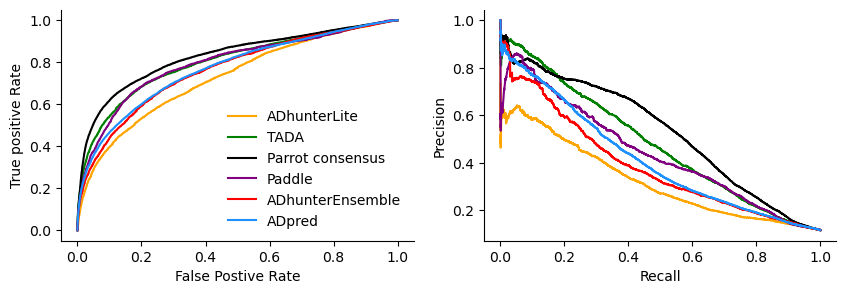

In [9]:
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axs = plt.subplots(1, 2, figsize=(10, 3))

adhunterlite_fpr, adhunterlite_tpr, _ = roc_curve(real_ls, adhunterlite_pred_ls)
tada_fpr, tada_tpr, _ = roc_curve(real_ls, tada_pred_ls)
parrot_fpr, parrot_tpr, _ = roc_curve(real_ls, parrot_ls)
paddle_fpr, paddle_tpr, _ = roc_curve(real_ls, paddle_ls)
adhunter_e_fpr, adhunter_e_tpr, _ = roc_curve(real_ls, adhunterensemble_ls)
adpred_fpr, adpred_tpr, _ = roc_curve(real_ls, adpred_ls)

adhunterlite_prec, adhunterlite_rec, adhunterlite_thresh = precision_recall_curve(real_ls, adhunterlite_pred_ls)
tada_prec, tada_rec, tada_thresh = precision_recall_curve(real_ls, tada_pred_ls)
parrot_prec, parrot_rec, parrot_thresh = precision_recall_curve(real_ls, parrot_ls)
paddle_prec, paddle_rec, paddle_thresh = precision_recall_curve(real_ls, paddle_ls)
adhunter_e_prec, adhunter_e_rec, adhunter_e_thresh = precision_recall_curve(real_ls, adhunterensemble_ls)
adpred_prec, adpred_rec, adpred_thresh = precision_recall_curve(real_ls, adpred_ls)

axs[0].plot(adhunterlite_fpr, adhunterlite_tpr, label='ADhunterLite', color = color_dict['ADhunterLite'])
axs[0].plot(tada_fpr, tada_tpr, label='TADA', color = color_dict['TADA'])
axs[0].plot(parrot_fpr, parrot_tpr, label='Parrot consensus', color = 'black')
axs[0].plot(paddle_fpr, paddle_tpr, label='Paddle', color = color_dict['Paddle'])
axs[0].plot(adhunter_e_fpr, adhunter_e_tpr, label='ADhunterEnsemble', color = color_dict['ADhunterEnsemble'])
axs[0].plot(adpred_fpr, adpred_tpr, label='ADpred', color = color_dict['ADpred'])
axs[0].legend(frameon=False)
axs[0].set_xlabel("False Postive Rate")
axs[0].set_ylabel("True positive Rate")

axs[1].plot(adhunterlite_rec, adhunterlite_prec,  label='ADhunterLite', color = color_dict['ADhunterLite'])
axs[1].plot(tada_rec, tada_prec, label='TADA', color = color_dict['TADA'])
axs[1].plot(parrot_rec, parrot_prec, label='Parrot consensus', color='black')
axs[1].plot(paddle_rec, paddle_prec, label='Paddle', color = color_dict['Paddle'])
axs[1].plot(adhunter_e_rec, adhunter_e_prec, label='ADhunterEnsemble', color = color_dict['ADhunterEnsemble'])
axs[1].plot(adpred_rec, adpred_prec, label='ADpred', color = color_dict['ADpred'])
axs[1].set_xlabel("Recall")
axs[1].set_ylabel("Precision")

sns.despine()

# Doing it the hard way

In [10]:
# All true positives
tp = overlap(merged_individual.loc[0], ad_coords_col='tada_intervals')
fp = predicted_not_true(merged_individual.loc[0], ad_coords_col='tada_intervals')
fn = true_not_predicted(merged_individual.loc[0], ad_coords_col='tada_intervals')

In [11]:
precision = tp / (tp + fp)
precision

0.3401360544217687

In [12]:
recall = tp / (tp + fn)
recall

0.5555555555555556

In [13]:
# Beacuse the threshold biases the F1 score so much, I think PRC curves are a better choice

def calculate_precision_recall_tada(threshold):
    intervals = make_tada_intervals(individual_predictions, threshold)
    if intervals is None: # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['TADA'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_paddle(threshold):
    intervals = make_paddle_intervals(individual_predictions, threshold)
    if intervals is None: # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))
    
    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['PADDLE'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_adhunterlite(threshold):
    intervals = make_adhunter_intervals(individual_predictions, threshold)
    if intervals is None: # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['ADHunter'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_adhunterensemble(threshold):
    intervals = make_adhunter_ensemble_intervals(individual_predictions, threshold)
    if intervals is None: # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['ADHunter_ensemble'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_adpred(threshold):
    intervals = make_adpred_intervals(individual_predictions, threshold)
    if (intervals is None) or (len(intervals) == 0): # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['ADPred'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_parrot(threshold, consensus_preds=consensus_preds):
    consensus_preds['predicted_AD_coords'] = consensus_preds['preds'].apply(AD_coords, threshold=threshold)

    merged = consensus_preds.merge(data, on=['name', 'sequence'], how='right')
    tp = merged.apply(overlap, ad_coords_col='predicted_AD_coords', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='predicted_AD_coords', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='predicted_AD_coords', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='predicted_AD_coords', axis=1).sum()

    parrot_r = tp / (tp + fn)

    if (tp + fp) == 0: 
        parrot_p = 1
    else: 
        parrot_p = tp / (tp + fp)

    parrot_tpr = tp / (tp + fn) # This is the same as recall
    parrot_fpr = fp / (fp + tn)

    return parrot_r, parrot_p, parrot_fpr, parrot_tpr



In [14]:
# protein_length-52 -1 is the final tile start

In [15]:
adhunter_e_recalls = []
adhunter_e_precisions = []
adhunter_e_fpr = []
adhunter_e_tpr = []

for threshold in tqdm(adhunter_e_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_adhunterensemble(threshold)
    adhunter_e_recalls.append(r)
    adhunter_e_precisions.append(p)    
    adhunter_e_fpr.append(fpr)
    adhunter_e_tpr.append(tpr)

100%|██████████| 81316/81316 [1:30:25<00:00, 14.99it/s]  


In [16]:
threshold

np.float64(1.2783875465393066)

In [17]:
adpred_recalls = []
adpred_precisions = []
adpred_fpr = []
adpred_tpr = []

for threshold in tqdm(adpred_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_adpred(threshold)
    adpred_recalls.append(r)
    adpred_precisions.append(p)    
    adpred_fpr.append(fpr)
    adpred_tpr.append(tpr)

100%|██████████| 97249/97249 [1:59:27<00:00, 13.57it/s]    


In [18]:
adhunter_l_recalls = []
adhunter_l_precisions = []
adhunter_l_fpr = []
adhunter_l_tpr = []

for threshold in tqdm(adhunterlite_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_adhunterlite(threshold)
    adhunter_l_recalls.append(r)
    adhunter_l_precisions.append(p)    
    adhunter_l_fpr.append(fpr)
    adhunter_l_tpr.append(tpr)

100%|██████████| 84567/84567 [4:36:44<00:00,  5.09it/s]     


In [19]:
paddle_recalls = []
paddle_precisions = []
paddle_fpr = []
paddle_tpr = []

for threshold in tqdm(paddle_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_paddle(threshold)
    paddle_recalls.append(r)
    paddle_precisions.append(p)    
    paddle_fpr.append(fpr)
    paddle_tpr.append(tpr)

100%|██████████| 82979/82979 [15:37:12<00:00,  1.48it/s]      


In [20]:
tada_recalls = []
tada_precisions = []
tada_fpr = []
tada_tpr = []

for threshold in tqdm(tada_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_tada(threshold)
    tada_recalls.append(r)
    tada_precisions.append(p)    
    tada_fpr.append(fpr)
    tada_tpr.append(tpr)

100%|██████████| 84264/84264 [1:24:57<00:00, 16.53it/s]


In [21]:
parrot_recalls = []
parrot_precisions = []
parrot_fpr = []
parrot_tpr = []

for threshold in tqdm(parrot_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_parrot(threshold)
    parrot_recalls.append(r)
    parrot_precisions.append(p)    
    parrot_fpr.append(fpr)
    parrot_tpr.append(tpr)

100%|██████████| 99473/99473 [24:58<00:00, 66.40it/s]  


In [22]:
pd.DataFrame({'parrot_recalls' : parrot_recalls,
              'parrot_precisions' : parrot_precisions,
              'parrot_fpr' : parrot_fpr,
              'parrot_tpr' : parrot_tpr}).to_csv('arf_parrot_roc_prc_data.csv')

In [23]:
pd.DataFrame({'tada_recalls' : tada_recalls,
              'tada_precisions' : tada_precisions,
              'tada_fpr' : tada_fpr,
              'tada_tpr' : tada_tpr}).to_csv('arf_tada_roc_prc_data.csv')

In [24]:
pd.DataFrame({'adpred_recalls' : adpred_recalls,
              'adpred_precisions' : adpred_precisions,
              'adpred_fpr' : adpred_fpr,
              'adpred_tpr' : adpred_tpr}).to_csv('arf_adpred_roc_prc_data.csv')

In [25]:
pd.DataFrame({'paddle_recalls' : paddle_recalls,
              'paddle_precisions' : paddle_precisions,
              'paddle_fpr' : paddle_fpr,
              'paddle_tpr' : paddle_tpr}).to_csv('arf_paddle_roc_prc_data.csv')

In [26]:
pd.DataFrame({'adhunter_l_recalls' : adhunter_l_recalls,
              'adhunter_l_precisions' : adhunter_l_precisions,
              'adhunter_l_fpr' : adhunter_l_fpr,
              'adhunter_l_tpr' : adhunter_l_tpr}).to_csv('arf_adhunter_l_roc_prc_data.csv')

In [27]:
pd.DataFrame({'adhunter_e_recalls' : adhunter_e_recalls,
              'adhunter_e_precisions' : adhunter_e_precisions,
              'adhunter_e_fpr' : adhunter_e_fpr,
              'adhunter_e_tpr' : adhunter_e_tpr}).to_csv('arf_adhunter_e_roc_prc_data.csv')

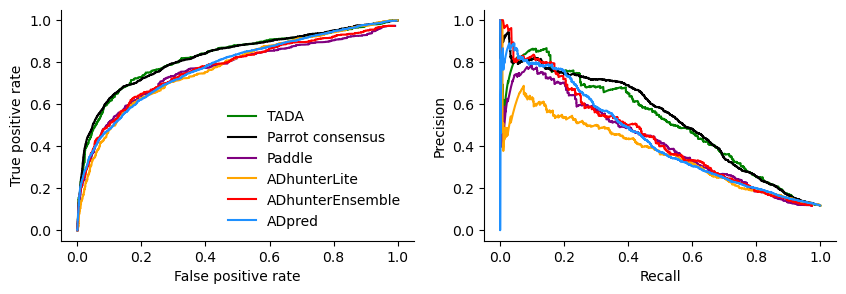

In [56]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3))

axs[0].plot(tada_fpr, tada_tpr, label='TADA', color=color_dict['TADA'])
axs[0].plot(parrot_fpr, parrot_tpr, label='Parrot consensus', color='black')
axs[0].plot(paddle_fpr, paddle_tpr, label='Paddle', color=color_dict['Paddle'])
axs[0].plot(adhunter_l_fpr, adhunter_l_tpr, label='ADhunterLite', color=color_dict['ADhunterLite'])
axs[0].plot(adhunter_e_fpr, adhunter_e_tpr, label='ADhunterEnsemble', color=color_dict['ADhunterEnsemble'])
axs[0].plot(adpred_fpr, adpred_tpr, label='ADpred', color=color_dict['ADpred'])
axs[0].set_xlabel("False positive rate")
axs[0].set_ylabel("True positive rate")
axs[0].legend(frameon=False)

axs[1].plot(tada_recalls, tada_precisions, label='TADA', color=color_dict['TADA'])
axs[1].plot(parrot_recalls, parrot_precisions, label='Parrot consensus', color='black')
axs[1].plot(paddle_recalls, paddle_precisions, label='Paddle', color=color_dict['Paddle']) 
axs[1].plot(adhunter_l_recalls, adhunter_l_precisions, label='ADhunterLite', color=color_dict['ADhunterLite'])
axs[1].plot(adhunter_e_recalls, adhunter_e_precisions, label='ADhunterEnsemble', color=color_dict['ADhunterEnsemble'])
axs[1].plot(adpred_recalls, adpred_precisions, label='ADpred', color=color_dict['ADpred'])
axs[1].set_xlabel("Recall")
axs[1].set_ylabel("Precision")

sns.despine()

plt.savefig("../figures/Arf_ROC_PRC.png", format='png')
plt.savefig("../figures/Arf_ROC_PRC.pdf", format='pdf')

In [57]:
from sklearn.metrics import auc

print(f"TADA PRC AUC: {auc(tada_recalls, tada_precisions):.3}")
print(f"Parrot consensus PRC AUC: {auc(parrot_recalls, parrot_precisions):.3}")
print(f"Paddle PRC AUC: {auc(paddle_recalls, paddle_precisions):.3}")
print(f"ADhunterLite PRC AUC: {auc(adhunter_l_recalls, adhunter_l_precisions):.3}")
print(f"ADhunterEnsemble PRC AUC: {auc(adhunter_e_recalls, adhunter_e_precisions):.3}")
print(f"ADpred PRC AUC: {auc(adpred_recalls, adpred_precisions):.3}")

TADA PRC AUC: 0.516
Parrot consensus PRC AUC: 0.53
Paddle PRC AUC: 0.418
ADhunterLite PRC AUC: 0.371
ADhunterEnsemble PRC AUC: 0.443
ADpred PRC AUC: 0.439


In [58]:
print(f"TADA PRC AUC: {auc(tada_fpr, tada_tpr):.3}")
print(f"Parrot consensus PRC AUC: {auc(parrot_fpr, parrot_tpr):.3}")
print(f"Paddle PRC AUC: {auc(paddle_fpr, paddle_tpr):.3}")
print(f"ADhunterLite PRC AUC: {auc(adhunter_l_fpr, adhunter_l_tpr):.3}")
print(f"ADhunterEnsemble PRC AUC: {auc(adhunter_e_fpr, adhunter_e_tpr):.3}")
print(f"ADpred PRC AUC: {auc(adpred_fpr, adpred_tpr):.3}")

TADA PRC AUC: 0.826
Parrot consensus PRC AUC: 0.828
Paddle PRC AUC: 0.758
ADhunterLite PRC AUC: 0.768
ADhunterEnsemble PRC AUC: 0.76
ADpred PRC AUC: 0.773


# Evaluate Arfs on the leave one out models

In [31]:
# Read in parrot model predictions
with open('arf_seqs_consensus_no_tada_preds.tsv', 'r') as f:
    lines = f.readlines()

names = []
seqs = []
pred_ls = []

for line in lines: 
    line = line.split()
    name = line[0]
    seq = line[1]
    preds = line[2:]
    preds = [float(p) for p in preds]
    names.append(name)
    seqs.append(seq)
    pred_ls.append(preds)

consensus_preds_no_tada = pd.DataFrame({'name' : names, 'sequence' : seqs, 'preds' : pred_ls})
# merged_consensus_no_tada = consensus_preds.merge(data, on=['name', 'sequence'], how='right') 

In [32]:
# Read in parrot model predictions
with open('arf_seqs_consensus_no_paddle_preds.tsv', 'r') as f:
    lines = f.readlines()

names = []
seqs = []
pred_ls = []

for line in lines: 
    line = line.split()
    name = line[0]
    seq = line[1]
    preds = line[2:]
    preds = [float(p) for p in preds]
    names.append(name)
    seqs.append(seq)
    pred_ls.append(preds)

consensus_preds_no_paddle= pd.DataFrame({'name' : names, 'sequence' : seqs, 'preds' : pred_ls})
# merged_consensus_no_tada = consensus_preds.merge(data, on=['name', 'sequence'], how='right') 

In [33]:
# Read in parrot model predictions
with open('arf_seqs_consensus_no_adpred_preds.tsv', 'r') as f:
    lines = f.readlines()

names = []
seqs = []
pred_ls = []

for line in lines: 
    line = line.split()
    name = line[0]
    seq = line[1]
    preds = line[2:]
    preds = [float(p) for p in preds]
    names.append(name)
    seqs.append(seq)
    pred_ls.append(preds)

consensus_preds_no_adpred= pd.DataFrame({'name' : names, 'sequence' : seqs, 'preds' : pred_ls})
# merged_consensus_no_tada = consensus_preds.merge(data, on=['name', 'sequence'], how='right') 

In [34]:
# Read in parrot model predictions
with open('arf_seqs_consensus_no_adhunterlite_preds.tsv', 'r') as f:
    lines = f.readlines()

names = []
seqs = []
pred_ls = []

for line in lines: 
    line = line.split()
    name = line[0]
    seq = line[1]
    preds = line[2:]
    preds = [float(p) for p in preds]
    names.append(name)
    seqs.append(seq)
    pred_ls.append(preds)

consensus_preds_no_adhunterlite= pd.DataFrame({'name' : names, 'sequence' : seqs, 'preds' : pred_ls})
# merged_consensus_no_tada = consensus_preds.merge(data, on=['name', 'sequence'], how='right') 

In [35]:
# Read in parrot model predictions
with open('arf_seqs_consensus_no_adhunterensemble_preds.tsv', 'r') as f:
    lines = f.readlines()

names = []
seqs = []
pred_ls = []

for line in lines: 
    line = line.split()
    name = line[0]
    seq = line[1]
    preds = line[2:]
    preds = [float(p) for p in preds]
    names.append(name)
    seqs.append(seq)
    pred_ls.append(preds)

consensus_preds_no_adhunterensemble= pd.DataFrame({'name' : names, 'sequence' : seqs, 'preds' : pred_ls})
# merged_consensus_no_tada = consensus_preds.merge(data, on=['name', 'sequence'], how='right') 

In [36]:
# Read in parrot model predictions
with open('arf_seqs_consensus_no_composition_preds.tsv', 'r') as f:
    lines = f.readlines()

names = []
seqs = []
pred_ls = []

for line in lines: 
    line = line.split()
    name = line[0]
    seq = line[1]
    preds = line[2:]
    preds = [float(p) for p in preds]
    names.append(name)
    seqs.append(seq)
    pred_ls.append(preds)

consensus_preds_no_composition= pd.DataFrame({'name' : names, 'sequence' : seqs, 'preds' : pred_ls})
# merged_consensus_no_tada = consensus_preds.merge(data, on=['name', 'sequence'], how='right') 

In [37]:
no_tada_recalls = []
no_tada_precisions = []
no_tada_fpr = []
no_tada_tpr = []

for threshold in tqdm(parrot_thresh[::100]):
    r, p, fpr, tpr = calculate_precision_recall_parrot(threshold, consensus_preds=consensus_preds_no_tada)
    no_tada_recalls.append(r)
    no_tada_precisions.append(p)    
    no_tada_fpr.append(fpr)
    no_tada_tpr.append(tpr)

100%|██████████| 995/995 [00:14<00:00, 69.69it/s]


In [38]:
no_paddle_recalls = []
no_paddle_precisions = []
no_paddle_fpr = []
no_paddle_tpr = []

for threshold in tqdm(parrot_thresh[::100]):
    r, p, fpr, tpr = calculate_precision_recall_parrot(threshold, consensus_preds=consensus_preds_no_paddle)
    no_paddle_recalls.append(r)
    no_paddle_precisions.append(p)    
    no_paddle_fpr.append(fpr)
    no_paddle_tpr.append(tpr)

100%|██████████| 995/995 [00:14<00:00, 66.96it/s] 


In [39]:
no_adpred_recalls = []
no_adpred_precisions = []
no_adpred_fpr = []
no_adpred_tpr = []

for threshold in tqdm(parrot_thresh[::100]):
    r, p, fpr, tpr = calculate_precision_recall_parrot(threshold, consensus_preds=consensus_preds_no_adpred)
    no_adpred_recalls.append(r)
    no_adpred_precisions.append(p)    
    no_adpred_fpr.append(fpr)
    no_adpred_tpr.append(tpr)

100%|██████████| 995/995 [00:14<00:00, 66.41it/s]


In [40]:
no_adhunterlite_recalls = []
no_adhunterlite_precisions = []
no_adhunterlite_fpr = []
no_adhunterlite_tpr = []

for threshold in tqdm(parrot_thresh[::100]):
    r, p, fpr, tpr = calculate_precision_recall_parrot(threshold, consensus_preds=consensus_preds_no_adhunterlite)
    no_adhunterlite_recalls.append(r)
    no_adhunterlite_precisions.append(p)    
    no_adhunterlite_fpr.append(fpr)
    no_adhunterlite_tpr.append(tpr)

100%|██████████| 995/995 [00:15<00:00, 65.67it/s]


In [41]:
no_adhunterensemble_recalls = []
no_adhunterensemble_precisions = []
no_adhunterensemble_fpr = []
no_adhunterensemble_tpr = []

for threshold in tqdm(parrot_thresh[::100]):
    r, p, fpr, tpr = calculate_precision_recall_parrot(threshold, consensus_preds=consensus_preds_no_adhunterensemble)
    no_adhunterensemble_recalls.append(r)
    no_adhunterensemble_precisions.append(p)    
    no_adhunterensemble_fpr.append(fpr)
    no_adhunterensemble_tpr.append(tpr)

100%|██████████| 995/995 [00:16<00:00, 60.97it/s]


In [42]:
no_composition_recalls = []
no_composition_precisions = []
no_composition_fpr = []
no_composition_tpr = []

for threshold in tqdm(parrot_thresh[::100]):
    r, p, fpr, tpr = calculate_precision_recall_parrot(threshold, consensus_preds=consensus_preds_no_composition)
    no_composition_recalls.append(r)
    no_composition_precisions.append(p)    
    no_composition_fpr.append(fpr)
    no_composition_tpr.append(tpr)

100%|██████████| 995/995 [00:15<00:00, 66.09it/s]


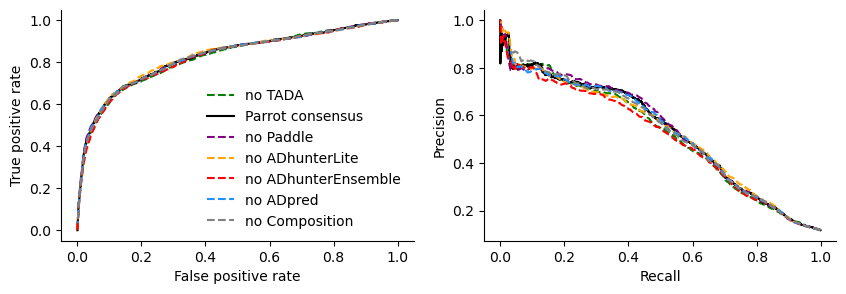

In [43]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3))

axs[0].plot(no_tada_fpr, no_tada_tpr, label='no TADA', color=color_dict['TADA'], linestyle='--')
axs[0].plot(parrot_fpr, parrot_tpr, label='Parrot consensus', color='black')
axs[0].plot(no_paddle_fpr, no_paddle_tpr, label='no Paddle', color=color_dict['Paddle'], linestyle='--')
axs[0].plot(no_adhunterlite_fpr, no_adhunterlite_tpr, label='no ADhunterLite', color=color_dict['ADhunterLite'], linestyle='--')
axs[0].plot(no_adhunterensemble_fpr, no_adhunterensemble_tpr, label='no ADhunterEnsemble', color=color_dict['ADhunterEnsemble'], linestyle='--')
axs[0].plot(no_adpred_fpr, no_adpred_tpr, label='no ADpred', color=color_dict['ADpred'], linestyle='--')
axs[0].plot(no_composition_fpr, no_composition_tpr, label='no Composition', color='grey', linestyle='--')
axs[0].set_xlabel("False positive rate")
axs[0].set_ylabel("True positive rate")
axs[0].legend(frameon=False)

axs[1].plot(no_tada_recalls, no_tada_precisions, label='no_TADA', color=color_dict['TADA'], linestyle='--')
axs[1].plot(parrot_recalls, parrot_precisions, label='Parrot consensus', color='black')
axs[1].plot(no_paddle_recalls, no_paddle_precisions, label='no Paddle', color=color_dict['Paddle'], linestyle='--') 
axs[1].plot(no_adhunterlite_recalls, no_adhunterlite_precisions, label='no ADhunterLite', color=color_dict['ADhunterLite'], linestyle='--')
axs[1].plot(no_adhunterensemble_recalls, no_adhunterensemble_precisions, label='no ADhunterEnsemble', color=color_dict['ADhunterEnsemble'], linestyle='--')
axs[1].plot(no_adpred_recalls, no_adpred_precisions, label='no ADpred', color=color_dict['ADpred'], linestyle='--')
axs[1].plot(no_composition_recalls, no_composition_precisions, label='no Composition', color='grey', linestyle='--')
axs[1].set_xlabel("Recall")
axs[1].set_ylabel("Precision")

sns.despine()

# plt.savefig("Arf_ROC_PRC.png", format='png')
# plt.savefig("Arf_ROC_PRC.pdf", format='pdf')

In [44]:
from sklearn.metrics import auc

print(f"Parrot consensus PRC AUC: {auc(parrot_recalls, parrot_precisions):.3}")
print(f"no TADA PRC AUC: {auc(no_tada_recalls, no_tada_precisions):.3}")
print(f"no Paddle PRC AUC: {auc(no_paddle_recalls, no_paddle_precisions):.3}")
print(f"no ADhunterLite PRC AUC: {auc(no_adhunterlite_recalls, no_adhunterlite_precisions):.3}")
print(f"no ADhunterEnsemble PRC AUC: {auc(no_adhunterensemble_recalls, no_adhunterensemble_precisions):.3}")
print(f"no ADpred PRC AUC: {auc(no_adpred_recalls, no_adpred_precisions):.3}")
print(f"no Composition PRC AUC: {auc(no_composition_recalls, no_composition_precisions):.3}")

Parrot consensus PRC AUC: 0.53
no TADA PRC AUC: 0.517
no Paddle PRC AUC: 0.534
no ADhunterLite PRC AUC: 0.525
no ADhunterEnsemble PRC AUC: 0.506
no ADpred PRC AUC: 0.497
no Composition PRC AUC: 0.497


In [45]:
print(f"Parrot consensus ROC AUC: {auc(parrot_fpr, parrot_tpr):.3}")
print(f"no TADA ROC AUC: {auc(no_tada_fpr, no_tada_tpr):.3}")
print(f"no Paddle ROC AUC: {auc(no_paddle_fpr, no_paddle_tpr):.3}")
print(f"no ADhunterLite ROC AUC: {auc(no_adhunterlite_fpr, no_adhunterlite_tpr):.3}")
print(f"no ADhunterEnsemble ROC AUC: {auc(no_adhunterensemble_fpr, no_adhunterensemble_tpr):.3}")
print(f"no ADpred ROC AUC: {auc(no_adpred_fpr, no_adpred_tpr):.3}")
print(f"no Composition ROC AUC: {auc(no_composition_fpr, no_composition_tpr):.3}")

Parrot consensus ROC AUC: 0.828
no TADA ROC AUC: 0.821
no Paddle ROC AUC: 0.828
no ADhunterLite ROC AUC: 0.826
no ADhunterEnsemble ROC AUC: 0.821
no ADpred ROC AUC: 0.827
no Composition ROC AUC: 0.826


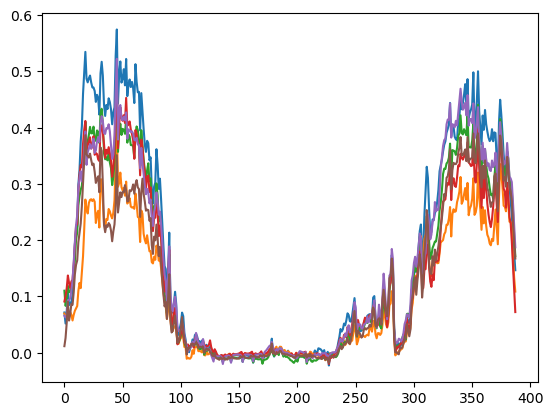

In [46]:
i = 2
plt.plot(consensus_preds_no_composition.loc[i, 'preds'])
plt.plot(consensus_preds_no_tada.loc[i, 'preds'])
plt.plot(consensus_preds.loc[i, 'preds'])
plt.plot(consensus_preds_no_paddle.loc[i, 'preds'])
plt.plot(consensus_preds_no_adhunterensemble.loc[i, 'preds'])
plt.plot(consensus_preds_no_adhunterlite.loc[i, 'preds'])

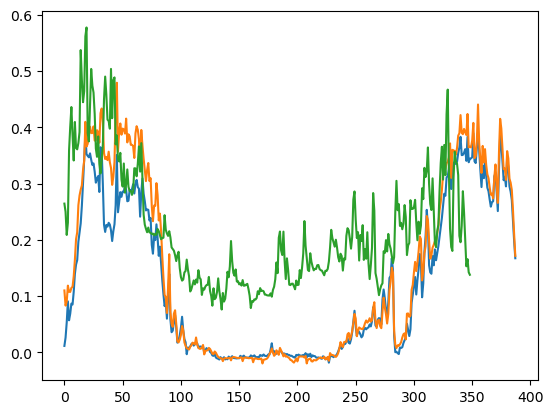

In [47]:
plt.plot(consensus_preds_no_adhunterlite.loc[i, 'preds'])
plt.plot(consensus_preds.loc[i, 'preds'])
plt.plot([a / 200000 for a in individual_predictions.loc[i, 'adhunter_preds']])

In [48]:
test = [0] * 53 * 2

In [49]:
test[27] = 1

In [50]:
len(test[(27-27):(27+26)])

53

In [51]:
53/2

26.5

In [52]:
572 + 26

598

In [53]:
len(individual_predictions.loc[0, 'sequence'])

598

In [54]:
individual_predictions.loc[0, 'paddle_centers']

[27.0,
 28.0,
 29.0,
 30.0,
 31.0,
 32.0,
 33.0,
 34.0,
 35.0,
 36.0,
 37.0,
 38.0,
 39.0,
 40.0,
 41.0,
 42.0,
 43.0,
 44.0,
 45.0,
 46.0,
 47.0,
 48.0,
 49.0,
 50.0,
 51.0,
 52.0,
 53.0,
 54.0,
 55.0,
 56.0,
 57.0,
 58.0,
 59.0,
 60.0,
 61.0,
 62.0,
 63.0,
 64.0,
 65.0,
 66.0,
 67.0,
 68.0,
 69.0,
 70.0,
 71.0,
 72.0,
 73.0,
 74.0,
 75.0,
 76.0,
 77.0,
 78.0,
 79.0,
 80.0,
 81.0,
 82.0,
 83.0,
 84.0,
 85.0,
 86.0,
 87.0,
 88.0,
 89.0,
 90.0,
 91.0,
 92.0,
 93.0,
 94.0,
 95.0,
 96.0,
 97.0,
 98.0,
 99.0,
 100.0,
 101.0,
 102.0,
 103.0,
 104.0,
 105.0,
 106.0,
 107.0,
 108.0,
 109.0,
 110.0,
 111.0,
 112.0,
 113.0,
 114.0,
 115.0,
 116.0,
 117.0,
 118.0,
 119.0,
 120.0,
 121.0,
 122.0,
 123.0,
 124.0,
 125.0,
 126.0,
 127.0,
 128.0,
 129.0,
 130.0,
 131.0,
 132.0,
 133.0,
 134.0,
 135.0,
 136.0,
 137.0,
 138.0,
 139.0,
 140.0,
 141.0,
 142.0,
 143.0,
 144.0,
 145.0,
 146.0,
 147.0,
 148.0,
 149.0,
 150.0,
 151.0,
 152.0,
 153.0,
 154.0,
 155.0,
 156.0,
 157.0,
 158.0,
 159.0,
 160.0,
 

In [55]:
test[(27-27):(27+26)] = [1] * 53